**Hotel Booking Data Analysis: Exploring Booking Patterns, Revenue Trends and Cancellation Behaviour**


In [62]:
#Importing needful libraries and importing the file, alongside a preview of the dataset for preliminary understanding.
#making a copy of the existing dataset so that any changes won't effect the original dataset if i need to refer back.

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df_raw = pd.read_csv(r"C:\Users\91944\Downloads\hotel_bookings.csv")
df = df_raw.copy()

print("Rows and columns:", df.shape)
display(df.head(10))

Rows and columns: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-15
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-15
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,02-07-15
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,02-07-15
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,03-07-15
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,03-07-15
6,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,NaN,NaN,0,Transient,107.0,0,0,Check-Out,03-07-15
7,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303.0,NaN,0,Transient,103.0,0,1,Check-Out,03-07-15
8,Resort Hotel,1,85,2015,July,27,1,0,3,2,...,No Deposit,240.0,NaN,0,Transient,82.0,0,1,Canceled,06-05-15
9,Resort Hotel,1,75,2015,July,27,1,0,3,2,...,No Deposit,15.0,NaN,0,Transient,105.5,0,0,Canceled,22-04-15


In [64]:
#The dataset has 119,390 bookings and 32 columns.

In [65]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,06-09-17
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,07-09-17
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,07-09-17
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,07-09-17
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,07-09-17


In [66]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [67]:
df.describe(include="all")

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,119390,119390.000000,119390.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,...,119390,103050.000000,6797.000000,119390.000000,119390,119390.000000,119390.000000,119390.000000,119390,119390
unique,2,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,926
top,City Hotel,NaN,NaN,NaN,August,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,21-10-15
freq,79330,NaN,NaN,NaN,13877,NaN,NaN,NaN,NaN,NaN,...,104641,NaN,NaN,NaN,89613,NaN,NaN,NaN,75166,1461
mean,NaN,0.370416,104.011416,2016.156554,NaN,27.165173,15.798241,0.927599,2.500302,1.856403,...,NaN,86.693382,189.266735,2.321149,NaN,101.831122,0.062518,0.571363,NaN,NaN
std,NaN,0.482918,106.863097,0.707476,NaN,13.605138,8.780829,0.998613,1.908286,0.579261,...,NaN,110.774548,131.655015,17.594721,NaN,50.535790,0.245291,0.792798,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,6.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,18.000000,2016.000000,NaN,16.000000,8.000000,0.000000,1.000000,2.000000,...,NaN,9.000000,62.000000,0.000000,NaN,69.290000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,69.000000,2016.000000,NaN,28.000000,16.000000,1.000000,2.000000,2.000000,...,NaN,14.000000,179.000000,0.000000,NaN,94.575000,0.000000,0.000000,NaN,NaN
75%,NaN,1.000000,160.000000,2017.000000,NaN,38.000000,23.000000,2.000000,3.000000,2.000000,...,NaN,229.000000,270.000000,0.000000,NaN,126.000000,0.000000,1.000000,NaN,NaN


***Data cleaning***

In [68]:
#identifying null values.

In [69]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [70]:
#Handling missing values
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0)
df["company"] = df["company"].fillna(0)
df["children"] = df["children"].fillna(0)

In [71]:
#checking for duplicate values

In [72]:
df.duplicated().sum()

np.int64(31994)

In [73]:
df = df.drop_duplicates()

In [74]:
print("Rows and columns:", df.shape)

Rows and columns: (87396, 32)


In [75]:
#The column names were standardised to improve consistency and readability throughout the analysis.

In [76]:
df.columns= (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

In [77]:
#Converting categorical variables into category data types

In [78]:
categorical_columns = [
    "hotel",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type",
    "customer_type",
    "reservation_status"
]

for i in categorical_columns:
    df[categorical_columns] = df[categorical_columns].astype("category")

In [79]:
#Converting numerical columns into appropriate data types

In [80]:
df['children'] = df['children'].astype(int)
df['agent'] = df['agent'].astype(int)
df['company'] = df['company'].astype(int)


In [81]:
#As noticed, the min value for ADR is a negative number- hence checking how many rows are there with negative values
print((df["adr"] < 0).sum())

1


In [82]:
#filtering df using >= 0, to remove this row and keeping rows where adr is 0 or positive
df = df[df["adr"] >= 0]

In [83]:
df.info()

<class 'pandas.DataFrame'>
Index: 87395 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   hotel                           87395 non-null  category
 1   is_canceled                     87395 non-null  int64   
 2   lead_time                       87395 non-null  int64   
 3   arrival_date_year               87395 non-null  int64   
 4   arrival_date_month              87395 non-null  str     
 5   arrival_date_week_number        87395 non-null  int64   
 6   arrival_date_day_of_month       87395 non-null  int64   
 7   stays_in_weekend_nights         87395 non-null  int64   
 8   stays_in_week_nights            87395 non-null  int64   
 9   adults                          87395 non-null  int64   
 10  children                        87395 non-null  int64   
 11  babies                          87395 non-null  int64   
 12  meal                            8

***Data Transformation***

In [84]:
#cheking how many total cancelled bookings
df['is_canceled'].value_counts()

is_canceled
0    63370
1    24025
Name: count, dtype: int64

In [85]:
#checking if no-show is checked as canceled.
df[df["is_canceled"] == 1]["reservation_status"].value_counts()

reservation_status
Canceled     23011
No-Show       1014
Check-Out        0
Name: count, dtype: int64

In [86]:
#total bookings whether cancelled or not
df["hotel"].value_counts()

hotel
City Hotel      53428
Resort Hotel    33967
Name: count, dtype: int64

In [87]:
#Examining cancellation counts by hotel type.
df.groupby('hotel')['is_canceled'].value_counts()

hotel         is_canceled
City Hotel    0              37379
              1              16049
Resort Hotel  0              25991
              1               7976
Name: count, dtype: int64

In [88]:
#City has 43% more confirmed booking than resort.

In [89]:
df['total_stays'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']

In [90]:
print(f"Bookings with 0 guests: {(df['total_guests'] == 0).sum()}")

Bookings with 0 guests: 166


In [91]:
#Removing bookings with zero guests using a boolean condition, the dataset was filtered to retain only reservations with at least one recorded guest.

In [92]:
df = df[df['total_guests'] > 0]

In [93]:
#Converting the reservation status date into datetime format

In [94]:
df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date'],
    format='%d-%m-%Y',
    errors='coerce'
)

In [95]:
#understanding to which year the dataset belongs to.

In [96]:
print("From year:", df["arrival_date_year"].min())
print("To year:  ", df["arrival_date_year"].max())

From year: 2015
To year:   2017


In [97]:
# Convert arrival date into a proper date format
df["arrival_date"] = pd.to_datetime(
    df["arrival_date_year"].astype(str) + "-" +
    df["arrival_date_month"] + "-" +
    df["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d")

In [98]:
#checking to which period the data covers.
print("Start date:", df["arrival_date"].min())
print("End date:  ", df["arrival_date"].max())

Start date: 2015-07-01 00:00:00
End date:   2017-08-31 00:00:00


***EDA***


In [99]:
#Checking further if the columns are categorised into numerical and categorial, thereby helps in deciding the appropriate analytical and visualisation techniques.

In [100]:
# Select numerical columns
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns

# Select categorical columns
categorical_columns = df.select_dtypes(include=["str", "category"]).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

Numerical Columns:
['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_stays', 'total_guests']

Categorical Columns:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status']


**HOTEL PERFORMANCE COMPARISON**

              Confirmed_Bookings  Cancellation %  Estimated Room Revenue  \
hotel                                                                      
City Hotel                 37239           30.10             12150577.73   
Resort Hotel               25981           23.48             10817034.22   

              Estimated Lost Revenue  
hotel                                 
City Hotel                6614455.63  
Resort Hotel              4869587.35  


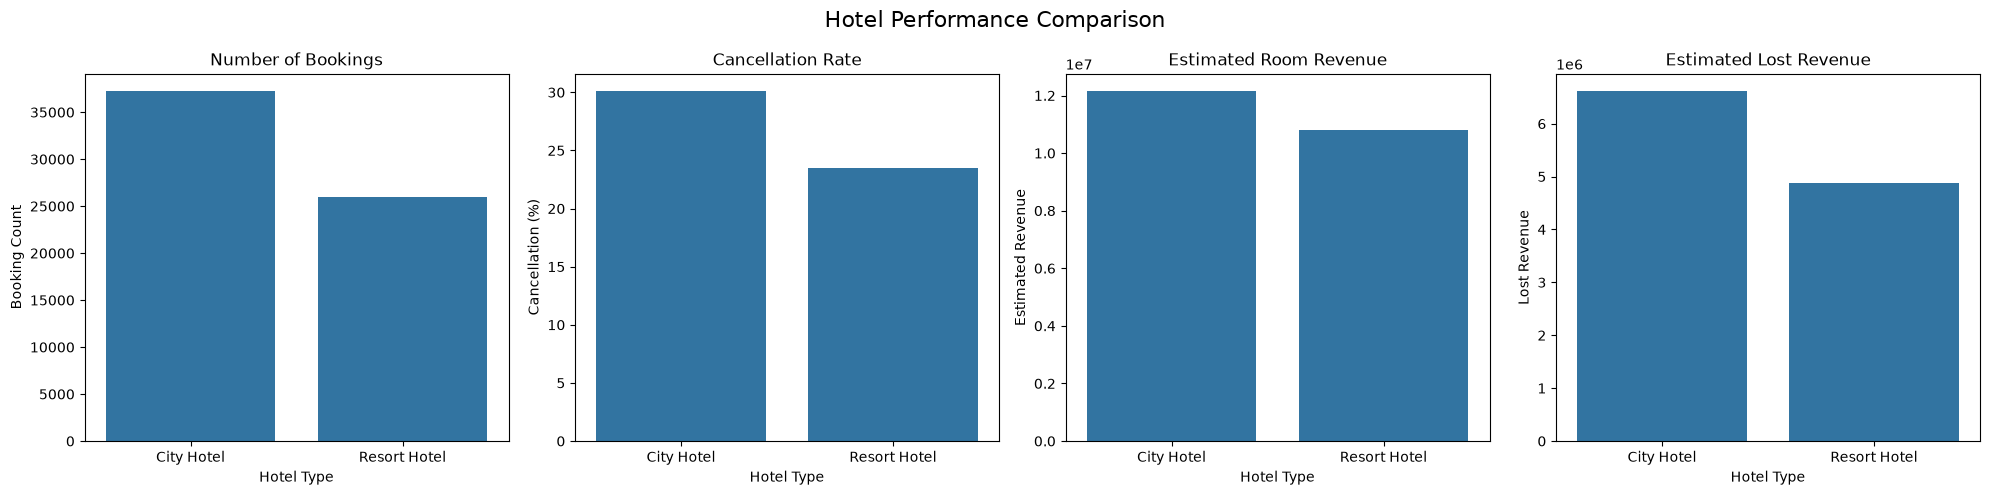

In [101]:
# Calculate number of bookings by hotel
confirmed_bookings = df[df["is_canceled"] == 0].groupby("hotel").size()

# Calculate cancellation percentage by hotel
cancellation = df.groupby("hotel")["is_canceled"].mean() * 100

# Calculate estimated room revenue for non-cancelled bookings
df["total_stays"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)
df["estimated_room_revenue"] = np.where(
    df["is_canceled"] == 0,
    df["adr"] * df["total_stays"],
    0)
revenue = df.groupby("hotel")["estimated_room_revenue"].sum()

# Calculate estimated lost revenue for cancelled bookings
df["estimated_lost_revenue"] = np.where(
    df["is_canceled"] == 1,
    df["adr"] * df["total_stays"],
    0)
lost_revenue = df.groupby("hotel")["estimated_lost_revenue"].sum()


# Combine the calculations into one summary table
summary = pd.DataFrame({
    "Confirmed_Bookings": confirmed_bookings,
    "Cancellation %": cancellation,
    "Estimated Room Revenue": revenue,
    "Estimated Lost Revenue": lost_revenue
})

print(summary.round(2))

# Create three graphs in one figure
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

sns.barplot(x=summary.index, y=summary["Confirmed_Bookings"], ax=axes[0])
axes[0].set_title("Number of Bookings")
axes[0].set_xlabel("Hotel Type")
axes[0].set_ylabel("Booking Count")

sns.barplot(x=summary.index, y=summary["Cancellation %"], ax=axes[1])
axes[1].set_title("Cancellation Rate")
axes[1].set_xlabel("Hotel Type")
axes[1].set_ylabel("Cancellation (%)")

sns.barplot(x=summary.index, y=summary["Estimated Room Revenue"], ax=axes[2])
axes[2].set_title("Estimated Room Revenue")
axes[2].set_xlabel("Hotel Type")
axes[2].set_ylabel("Estimated Revenue")

sns.barplot(x=summary.index, y=summary["Estimated Lost Revenue"], ax=axes[3])
axes[3].set_title("Estimated Lost Revenue")
axes[3].set_xlabel("Hotel Type")
axes[3].set_ylabel("Lost Revenue")

plt.suptitle("Hotel Performance Comparison", fontsize=16)
plt.tight_layout()
plt.show()

In [102]:
#checking whether the average length of stay effects this revenue change?
average_stay_length = df.groupby("hotel", observed=True)["total_stays"].mean().round(2)
print(average_stay_length)

hotel
City Hotel      3.14
Resort Hotel    4.39
Name: total_stays, dtype: float64


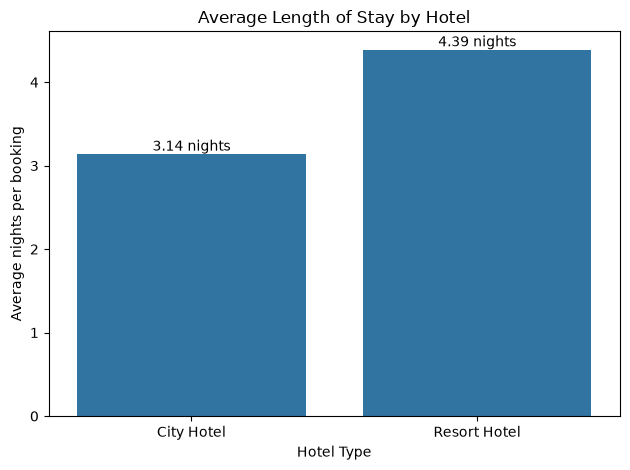

In [103]:
ax = sns.barplot(x=average_stay_length.index, y=average_stay_length.values)
ax.bar_label(ax.containers[0], fmt="%.2f nights")
ax.set_title("Average Length of Stay by Hotel")
ax.set_xlabel("Hotel Type")
ax.set_ylabel("Average nights per booking")
plt.tight_layout()
plt.show()

hotel
City Hotel      326.3
Resort Hotel    416.3
dtype: float64


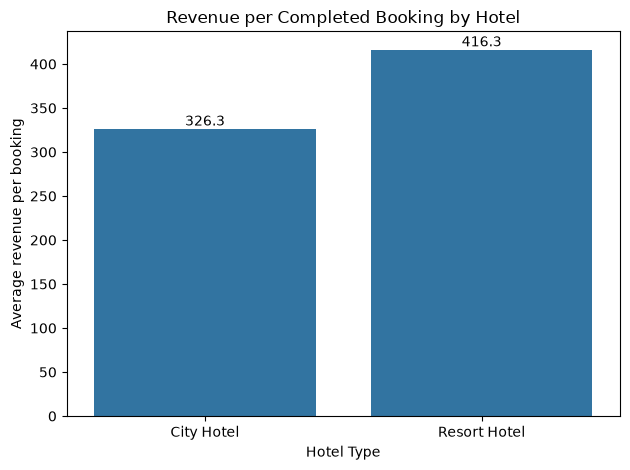

In [104]:
#Revenue per booking
# Revenue per completed booking = total revenue ÷ number of completed bookings
completed = df[df["is_canceled"] == 0]

revenue_total = completed.groupby("hotel")["estimated_room_revenue"].sum()
bookings_done = completed.groupby("hotel").size()

rev_per_booking = (revenue_total / bookings_done).round(1)
print(rev_per_booking)

ax = sns.barplot(x=rev_per_booking.index, y=rev_per_booking.values)
ax.bar_label(ax.containers[0], fmt="%.1f")
ax.set_title("Revenue per Completed Booking by Hotel")
ax.set_xlabel("Hotel Type")
ax.set_ylabel("Average revenue per booking")
plt.tight_layout()
plt.show()

Key Business Insights 

The comparative analysis of City Hotels and Resort Hotels reveals distinct differences in their booking volume, revenue generation, cancellation behaviour and customer stay patterns.

1. Booking Volume: City Hotels recorded 37,239 confirmed bookings, approximately 43.3% higher than Resort Hotels. This indicates stronger booking volume, although higher booking numbers do not necessarily translate into proportionately higher revenue.

2. Cancellation Rate: City Hotels recorded a cancellation rate of 30.10%, compared with 23.48% for Resort Hotels. This suggests greater booking instability and a need for stronger cancellation management strategies at City Hotels. City Hotel bookings are therefore approximately 28.19% more likely to be cancelled relative to the Resort Hotel cancellation rate. A hotel with a higher cancellation rate faces greater uncertainty in occupancy planning, room inventory management, staffing, and revenue forecasting.

3. Total Revenue: City Hotels generated approximately 12.15 million in estimated room revenue, compared with 10.82 million for Resort Hotels. Despite having considerably more bookings, their revenue advantage was only 12.3%.

4. Revenue per Booking: Resort Hotels generated approximately 416.30 per confirmed booking, compared with 326.30 for City Hotels, representing approximately 27.6% higher revenue per booking. This suggests that Resort Hotels extract greater revenue value from each confirmed reservation. Their longer average stay may partly explain this difference.

5. Average Length of Stay: Resort Hotels recorded an average stay of 4.39 nights, compared with 3.14 nights for City Hotels. This indicates a stronger extended-stay customer pattern at Resort Hotels and presents opportunities for accommodation packages and additional service offerings.The longer duration may partly explain why Resort Hotels generate greater revenue per confirmed booking. A guest staying for more nights creates more opportunities for room revenue and potentially additional spending on hotel services.

6. Estimated Lost Revenue: City Hotels recorded approximately 6.61 million in estimated lost revenue, compared with 4.87 million for Resort Hotels. Combined with their higher cancellation rate, this identifies City Hotels as the priority for cancellation-reduction initiatives.

7. Combined estimated lost revenue from cancelled bookings is approx 11,484,042.98. where taken this revenue calculation at hand city hotel accounts for approx 57.6% of this total estimated lost revenue. 

Recommendations

* City Hotels – Revenue Optimisation: Focus on increasing revenue per booking through extended-stay packages, room upgrades, bundled services and targeted upselling.
* City Hotels – Cancellation Management: Investigate high-cancellation customer segments, booking lead times and distribution channels. Introduce targeted retention strategies and suitable booking conditions.
* Resort Hotels – Customer Acquisition: Increase booking volume while protecting their higher revenue per booking through targeted marketing and customer acquisition campaigns.
* Resort Hotels – Revenue Maximisation: Capitalise on longer guest stays through premium experiences, recreational packages, food and beverage offerings and additional services.
* Both Hotel Types – Revenue Management: Implement differentiated pricing strategies based on seasonal demand, customer segments, booking patterns and room availability.

Conclusion

* City Hotels demonstrate a higher-volume booking model, generating greater total revenue but experiencing higher cancellation rates and lower revenue per booking. In contrast, Resort Hotels demonstrate stronger revenue generation per confirmed booking, longer customer stays and lower cancellation rates.
* Therefore, the primary opportunity for City Hotels is to improve booking value and retention, whereas Resort Hotels should focus on expanding booking volume while maintaining their existing revenue efficiency.

**SEASONAL DEMAND AND TREND**

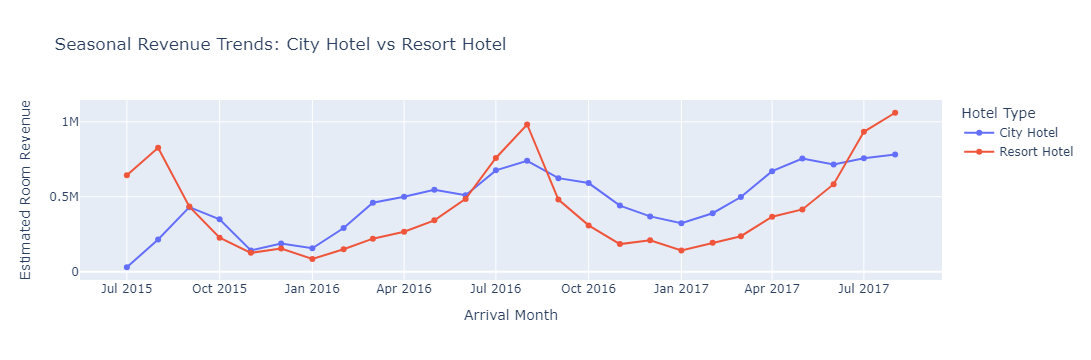

In [105]:
# SEASONAL DEMAND AND REVENUE
# Keep only bookings where the guest checked out
arrived = df[df["reservation_status"] == "Check-Out"].copy()

# Calculate total nights stayed
arrived["total_nights"] = (
    arrived["stays_in_weekend_nights"] +
    arrived["stays_in_week_nights"]
)

# Calculate estimated room revenue
arrived["estimated_revenue"] = (
    arrived["adr"] * arrived["total_nights"]
)
# Create a date using the arrival year and month
arrived["arrival_month"] = pd.to_datetime(
    arrived["arrival_date_year"].astype(str) + "-" +
    arrived["arrival_date_month"] + "-01",
    format="%Y-%B-%d"
)

# Group bookings by arrival month
monthly_hotel = arrived.groupby(
    ["arrival_month", "hotel"]
).agg(
    completed_bookings=("hotel", "size"),
    estimated_revenue=("estimated_revenue", "sum")
).reset_index()

fig = px.line(
    monthly_hotel,
    x="arrival_month",
    y="estimated_revenue",
    color="hotel",
    markers=True,
    title="Seasonal Revenue Trends: City Hotel vs Resort Hotel",
    labels={
        "arrival_month": "Arrival Month",
        "estimated_revenue": "Estimated Room Revenue",
        "hotel": "Hotel Type"
    }
)

fig.update_layout(
    hovermode="x unified",
    xaxis_title="Arrival Month",
    yaxis_title="Estimated Room Revenue"
)

fig.show()

**Investigating Cancellation Differences Between Hotel Types**

In [106]:
# what booking characteristics are associated with cancellations?
# comparing cancellation rates across the four factors- lead time, market segment, deposit, customer type. 

In [107]:
# Create a copy so we do not change the original dataset
cancel_df = df.copy()

# Divide lead time into groups
cancel_df["lead_time_group"] = pd.cut(
    cancel_df["lead_time"],
    bins=[-1, 7, 30, 90, 180, float("inf")],
    labels=[
        "0–7 days",
        "8–30 days",
        "31–90 days",
        "91–180 days",
        "181+ days"
    ]
)

In [108]:
# Calculate cancellation percentage for each group
lead_time_cancel = (
    cancel_df.groupby(
        ["hotel", "lead_time_group"], observed=True
    )["is_canceled"].mean().mul(100).reset_index()
)

market_cancel = (
    cancel_df.groupby(
        ["hotel", "market_segment"]
    )["is_canceled"].mean().mul(100).reset_index()
)

deposit_cancel = (
    cancel_df.groupby(
        ["hotel", "deposit_type"]
    )["is_canceled"].mean().mul(100).reset_index()
)

customer_cancel = (
    cancel_df.groupby(
        ["hotel", "customer_type"]
    )["is_canceled"].mean().mul(100).reset_index()
)

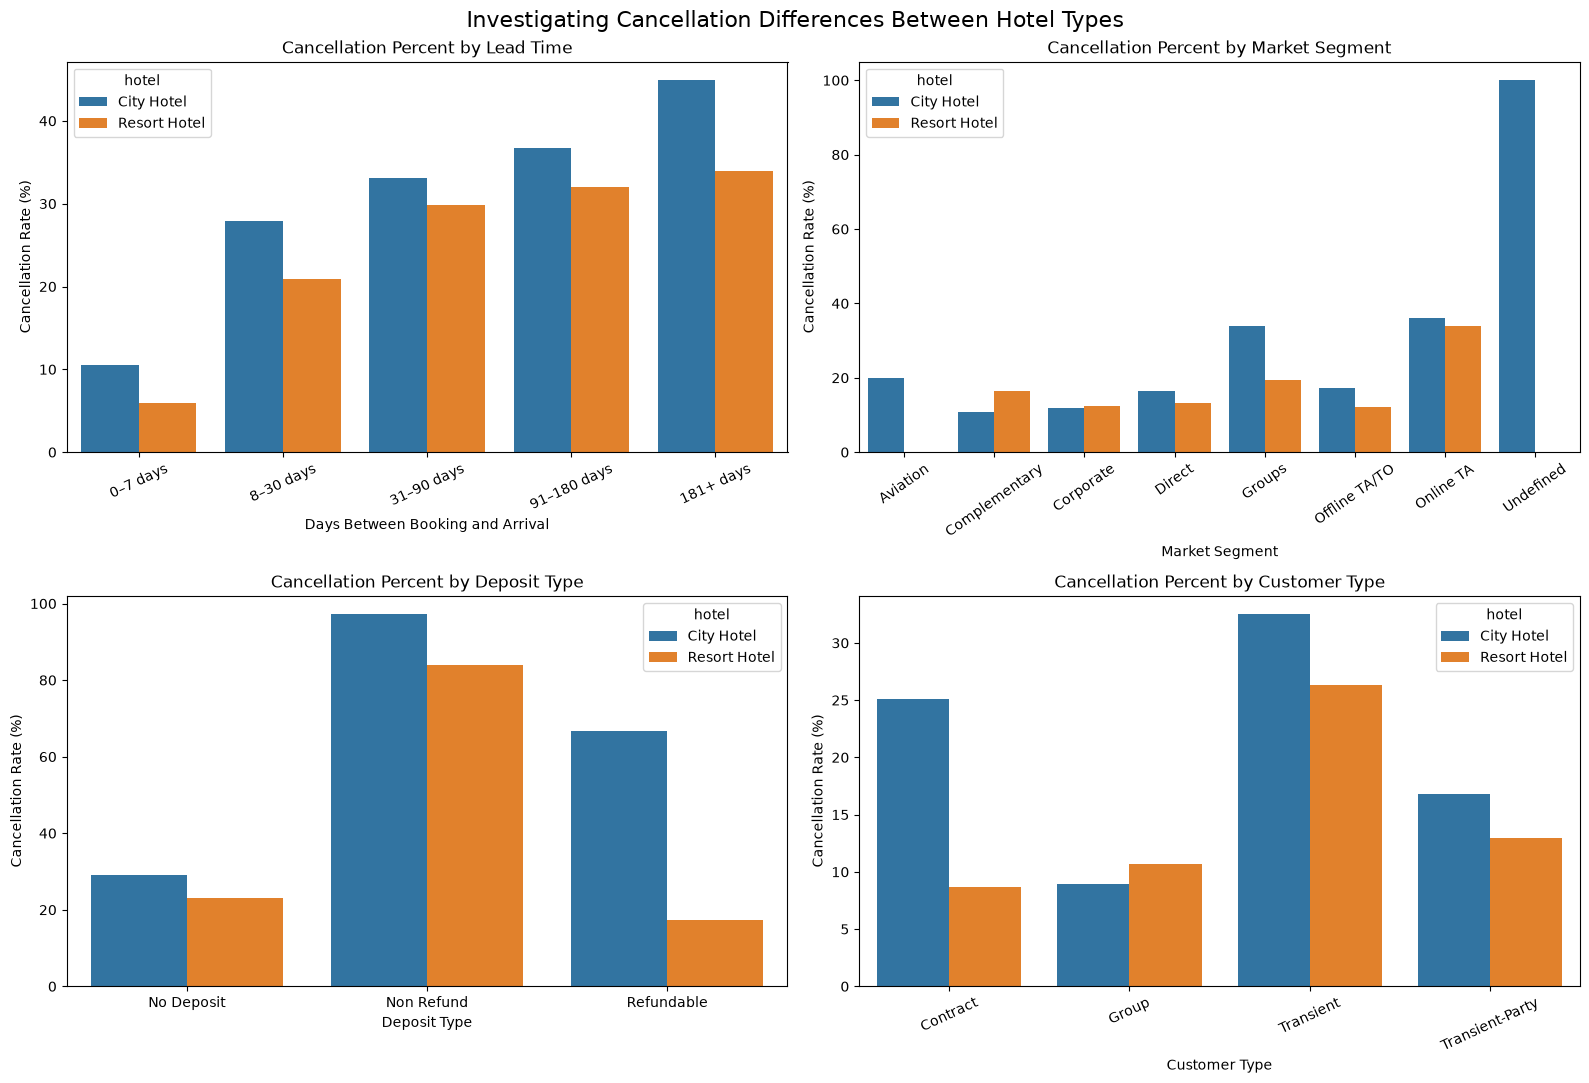

In [109]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.barplot(
    data=lead_time_cancel,
    x="lead_time_group",
    y="is_canceled",
    hue="hotel",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Cancellation Percent by Lead Time")
axes[0, 0].set_xlabel("Days Between Booking and Arrival")
axes[0, 0].set_ylabel("Cancellation Rate (%)")
axes[0, 0].tick_params(axis="x", rotation=25)

sns.barplot(
    data=market_cancel,
    x="market_segment",
    y="is_canceled",
    hue="hotel",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Cancellation Percent by Market Segment")
axes[0, 1].set_xlabel("Market Segment")
axes[0, 1].set_ylabel("Cancellation Rate (%)")
axes[0, 1].tick_params(axis="x", rotation=35)

sns.barplot(
    data=deposit_cancel,
    x="deposit_type",
    y="is_canceled",
    hue="hotel",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Cancellation Percent by Deposit Type")
axes[1, 0].set_xlabel("Deposit Type")
axes[1, 0].set_ylabel("Cancellation Rate (%)")

sns.barplot(
    data=customer_cancel,
    x="customer_type",
    y="is_canceled",
    hue="hotel",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Cancellation Percent by Customer Type")
axes[1, 1].set_xlabel("Customer Type")
axes[1, 1].set_ylabel("Cancellation Rate (%)")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.suptitle(
    "Investigating Cancellation Differences Between Hotel Types",
    fontsize=16
)
plt.tight_layout()
plt.show()


Since the cancellation rate is higher for City Hotel, as proven by previous analysis, let's look into the general characteristics of cancellation behaviour-
* Cancellation rate vs lead time- Bookings made far in advance may be more exposed to uncertainty because customers have more time to change travel plans. The stronger cancellation pattern at City Hotels suggests that long-lead bookings may be a particularly vulnerable booking category.

**HOTEL BOOKINGS BY GUEST COUNTRIES**

In [110]:
#Count bookings per country, sort high to low, keep the top 10
#identifying using the three-letter country code and using plotly's px.choropleth to create a geographical heatmap.

In [111]:
#identifying country code less than three letters.
not_three = df[df["country"].str.len() != 3]
print(not_three["country"].value_counts())

country
CN         1093
Unknown     447
ABW           0
AGO           0
AIA           0
           ... 
VGB           0
VNM           0
ZAF           0
ZMB           0
ZWE           0
Name: count, Length: 178, dtype: int64


In [112]:
df["country"] = df["country"].replace({"CN": "CHN"})

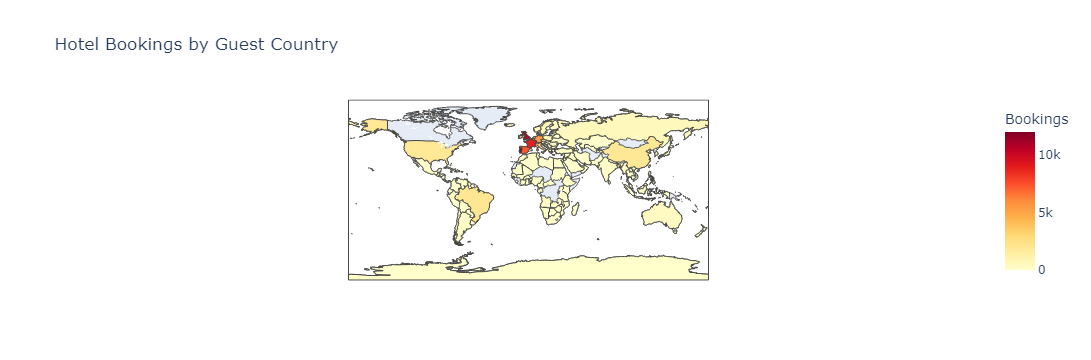

In [113]:
#Count bookings per country code
country_bookings = df.groupby("country")["hotel"].count().reset_index(name="Bookings")

#Remove rows that are not valid 3-letter codes ('Unknown' and the 2-letter 'CN')
country_bookings = country_bookings[country_bookings["country"].str.len() == 3]

#Geographical heatmap
fig = px.choropleth(
    country_bookings,
    locations="country",               # the 3-letter codes
    color="Bookings",
    color_continuous_scale="YlOrRd",   # darker = more bookings
    range_color=[0, 12000],            # stops Portugal from washing out the other countries
    title="Hotel Bookings by Guest Country"
)
fig.show()

In [114]:
#Bookings and revenue per country
country_table = df.groupby("country").agg(
    Bookings=("hotel", "count"),
    Revenue=("estimated_room_revenue", "sum"))
#Revenue share (% of total revenue from all countries)
country_table["Revenue Share %"] = country_table["Revenue"] / country_table["Revenue"].sum() * 100

#Top 10 by bookings, highest first
top10 = (country_table.sort_values("Bookings", ascending=False)
                      .head(10)[["Bookings", "Revenue Share %"]])

#Coloured table
top10.style \
    .background_gradient(cmap="YlOrRd", subset=["Bookings"]) \
    .background_gradient(cmap="Blues", subset=["Revenue Share %"]) \
    .format({"Bookings": "{:,}", "Revenue Share %": "{:.2f}%"}) \
    .set_caption("Top 10 Countries: Bookings and Share of Revenue")

,Bookings,Revenue Share %
country,,
PRT,"27,355",21.11%
GBR,"10,423",16.22%
FRA,"8,823",11.92%
ESP,"7,244",8.79%
DEU,"5,385",7.07%
ITA,"3,061",3.23%
IRL,"3,015",5.11%
BEL,"2,081",3.01%
BRA,"1,993",1.94%


* Portugal (PRT) is the dominant source market,followed by the United Kingdom (GBR), France (FRA), Spain (ESP), and Germany (DEU).

Business Strategies
* Country specific promotional campaigns such as country specific holiday and seasonal promotions.
* Multilingual booking support
* Targeted digital advertising

Total repeat bookings: 3363


,market_segment,Repeat Guests
2,Corporate,1442
3,Direct,774
6,Online TA,554
5,Offline TA/TO,255
1,Complementary,221
0,Aviation,63
4,Groups,54


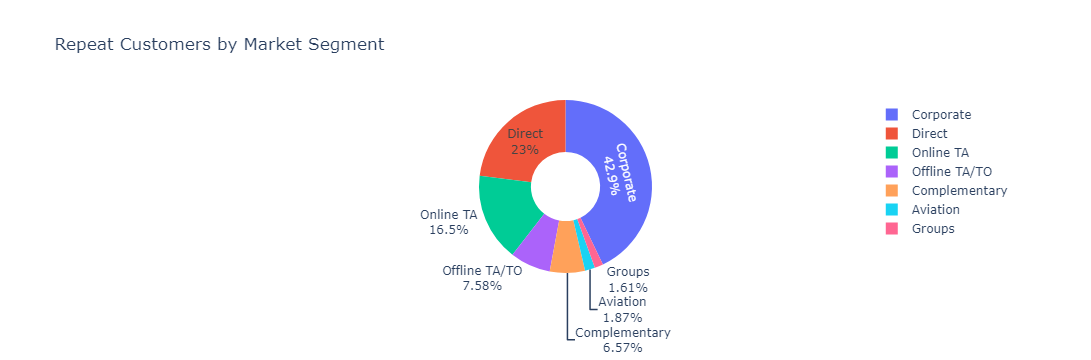

In [115]:
#Repeat customers by market segment
#keep only repeated guests
repeat_customers = df[df["is_repeated_guest"] == 1]
#repeat guests by market segment
repeat_segment =  (repeat_customers.groupby("market_segment")
                        .size()
                        .reset_index(name="Repeat Guests")
                        .sort_values("Repeat Guests", ascending=False))

print("Total repeat bookings:", len(repeat_customers))
display(repeat_segment)
#pie chart
fig = px.pie(
    repeat_segment,
    names="market_segment",
    values="Repeat Guests",
    hole=0.4,
    title="Repeat Customers by Market Segment"
)
fig.update_traces(textinfo="percent+label")
fig.show()


* Corporate bookings account for approximately 42.87% of all repeat guest bookings.And arounf 23.01% accounts to direct booking. Therefore, approximately 65.87% of repeat guest bookings originate from Corporate and Direct segments.
* Hence these two channels are therefore particularly important for repeat guest acquisition and retention strategies such as loyalty programs, guest benefits, personalised offers and repeat booking discounts.

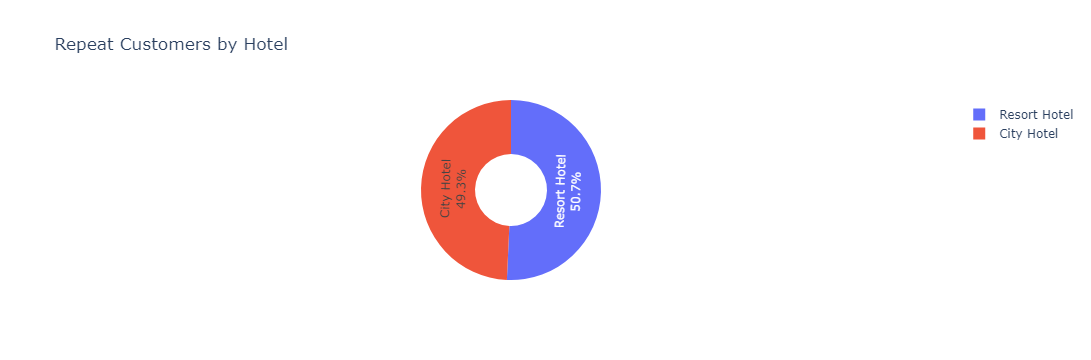

In [116]:
#Repeat customers by hotel type.
repeat = df[df["is_repeated_guest"] == 1]

repeat_hotel = (repeat.groupby("hotel")
                      .size()
                      .reset_index(name="Repeat Guests"))

fig = px.pie(repeat_hotel, names="hotel", values="Repeat Guests", hole=0.4,
             title="Repeat Customers by Hotel")
fig.update_traces(textinfo="percent+label")
fig.show()

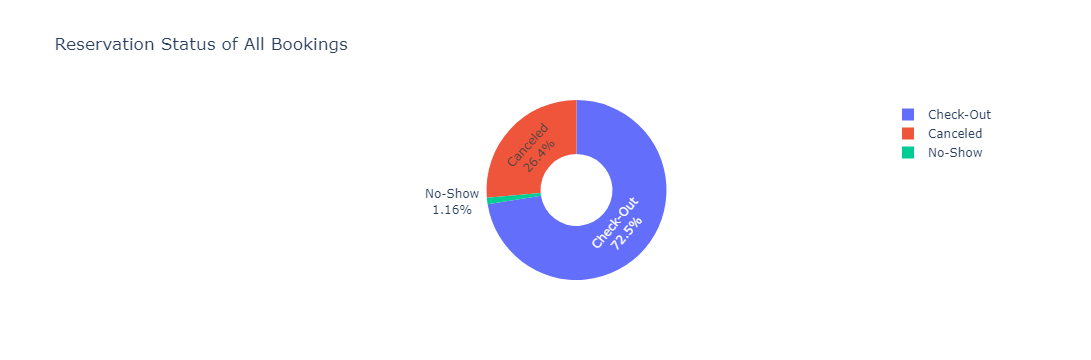

In [117]:
#Pie chart of reservation status
status = df["reservation_status"].value_counts().reset_index()
status.columns = ["Reservation Status", "Bookings"]

fig = px.pie(status, names="Reservation Status", values="Bookings", hole=0.4,
             title="Reservation Status of All Bookings")
fig.update_traces(textinfo="percent+label")
fig.show()

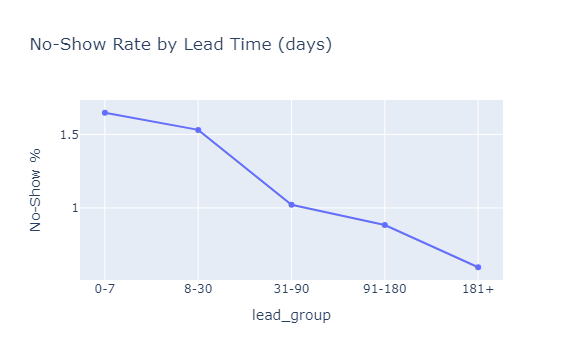

  lead_group  No-Show %
0        0-7       1.65
1       8-30       1.53
2      31-90       1.02
3     91-180       0.88
4       181+       0.60


In [123]:
#Is no-show due to lead time?
df["is_no_show"] = (df["reservation_status"] == "No-Show").astype(int)
df["lead_group"] = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, float("inf")],
                          labels=["0-7", "8-30", "31-90", "91-180", "181+"])

noshow_rate = (df.groupby("lead_group", observed=True)["is_no_show"].mean() * 100
                 ).reset_index(name="No-Show %")

fig = px.line(noshow_rate, x="lead_group", y="No-Show %", markers=True,
              title="No-Show Rate by Lead Time (days)")
fig.show()
print(noshow_rate.round(2))

* The line plot slopes the other way. the no-show rate fails as lead time grows.
* From 1.65% for bookings made 0-7 days ahead to 0.60% for 181+ days. 
* Last minute bookings most likely simply does not turn up.
* Possible approaches to account for such no-show revenue loss could be automated pre-arrival confirmations, arrival day reminders etc.



In [119]:
# Distribution channel scatterplot
df[df["is_canceled"] == 0]["distribution_channel"].value_counts()

distribution_channel
TA/TO        47628
Direct       11030
Corporate     4416
GDS            145
Undefined        1
Name: count, dtype: int64

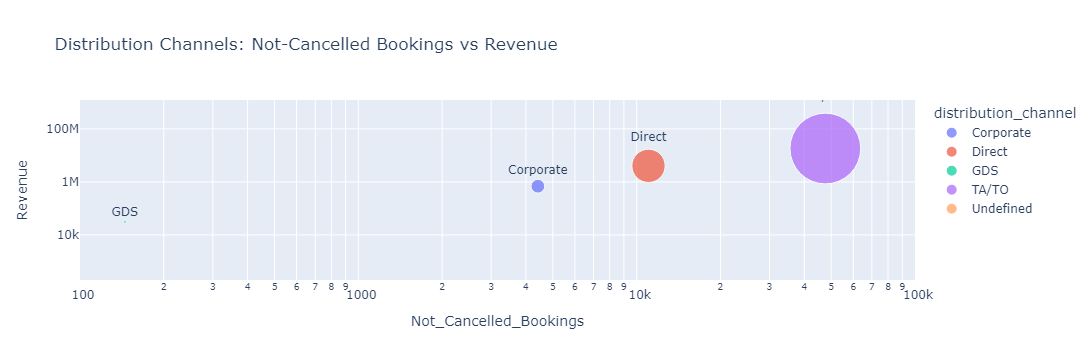

In [120]:
#Keep only bookings that were NOT cancelled
kept = df[df["is_canceled"] == 0]

#For each channel: count the kept bookings and add up the revenue
channel = kept.groupby("distribution_channel").agg(
    Not_Cancelled_Bookings=("hotel", "count"),
    Revenue=("estimated_room_revenue", "sum")
).reset_index()

#Scatter plot
fig = px.scatter(
    channel,
    x="Not_Cancelled_Bookings",
    y="Revenue",
    color="distribution_channel",
    text="distribution_channel",
    size="Revenue",
    size_max=50,
    log_x=True,
    log_y=True,
    range_x=[100, 100000],
    title="Distribution Channels: Not-Cancelled Bookings vs Revenue"
)
fig.update_traces(textposition="top center")
fig.show()


Travel agencies and tour operators contribute the largest number of confirmed bookings

In [121]:
#Top 10 agencies where bookings were confirmed
#Keep only confirmed (not cancelled) bookings, and remove agent 0 (= no agent recorded)
confirmed = df[(df["is_canceled"] == 0) & (df["agent"] != 0)]
top10_agents = (confirmed.groupby("agent")
                         .size()
                         .sort_values(ascending=False)
                         .head(10))
print(top10_agents)

agent
9      17199
240     8084
7       2858
14      2759
250     2285
241     1426
28      1406
8        998
6        939
40       909
dtype: int64


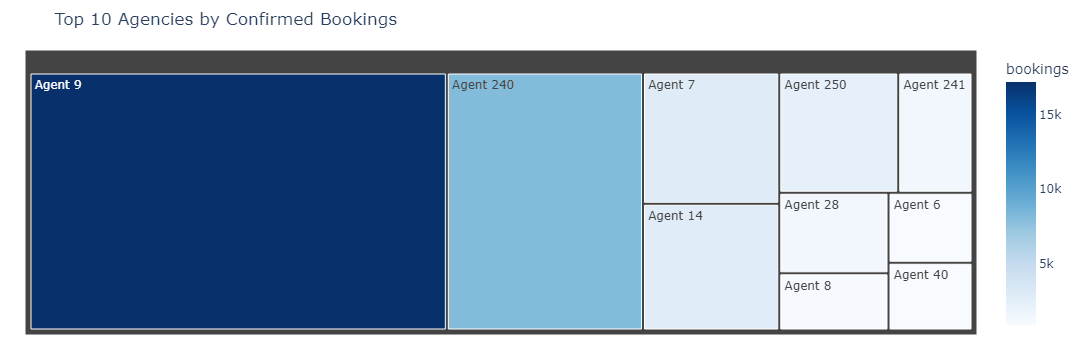

In [122]:
#convert the series into data frame.
df_agents = top10_agents.reset_index(name='bookings')
#convert the numbers to strings for categorical grouping
df_agents['agent'] = 'Agent ' + df_agents['agent'].astype(str)
#treemap
fig = px.treemap(
    df_agents,
    path=['agent'],
    values='bookings',
    title='Top 10 Agencies by Confirmed Bookings',
    color='bookings',
    color_continuous_scale='Blues'
)

fig.update_layout(margin=dict(t=50, l=25, r=25, b=25))
fig.show()


Business implication
* The hotel should strengthen relationships with high-performing agents while avoiding excessive reliance on a small number of booking partners.
* Further analyse the revenue generated by each agent, evaluate commission costs, and develop partnerships with high-performing agents.

Note

* Cancellation behaviour varies considerably across market segments, with Online Travel Agency (Online TA) bookings exhibiting relatively high cancellation rates across both City Hotels and Resort Hotels.
* However, this finding does not necessarily contradict the distribution channel analysis, which indicates that travel agency and tour operator channels contribute substantially to confirmed bookings and estimated room revenue.
* The distinction lies in the metrics being evaluated: cancellation rates measure the proportion of bookings that are cancelled, whereas confirmed booking counts and estimated revenue reflect reservations that successfully materialized.
* Therefore, despite experiencing relatively higher cancellation rates, Online TA bookings may still contribute significantly to hotel revenue because of their large booking volume. This suggests that online travel agencies represent both an important revenue-generating source and a segment associated with higher booking uncertainty. 